In [ ]:
!pip install coremltools
!pip install scikit-learn==1.5.*

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 51.6 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


predicted gamit ung test set na 30%
['High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low' 'High' 'High'
 'High' 'High' 'High' 'Low' 'High' 'High' 'High' 'Low' 'Low' 'High' 'Low'
 'Low' 'High' 'High' 'High' 'High' 'High' 'High' 'High' 'Low']
Confusion Matrix:
[[10  0  0]
 [ 0  7  0]
 [13  0  0]]
Classification Report:
              precision    recall  f1-score   support

        High       0.43      1.00      0.61        10
         Low       1.00      1.00      1.00         7
      Medium       0.00      0.00      0.00        13

    accuracy                           0.57        30
   macro avg       0.48      0.67      0.54        30
weighted avg       0.38      0.57      0.44        30

Accuracy: 0.5666666666666667


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


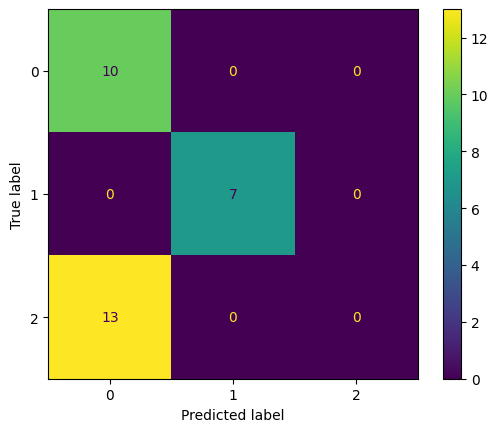

Predicted Stress Level: ['High']


Model saved as StressLevel.mlmodel


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
path = "/content/drive/MyDrive/datasets/studentStress.csv"
headernames = ['study_hours', 'sleep_hours', 'social_media_hours', 'exam_score','stress_level']

dataset = pd.read_csv(path)
dataset.head()

X = dataset.iloc[:,:-1].values
y = dataset.iloc[:, 4].values

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30)



from sklearn.tree import DecisionTreeClassifier
model= DecisionTreeClassifier(
    criterion='entropy',
    max_depth=1,
    min_samples_leaf=10,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("predicted gamit ung test set na 30%")
print(y_pred)
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
result = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(result)

result1 = classification_report(y_test, y_pred)
print("Classification Report:",)
print (result1)

result2 = accuracy_score(y_test,y_pred)
print("Accuracy:",result2)

# Plot a confusion matrix
from sklearn.metrics import classification_report, confusion_matrix,accuracy_score
from sklearn import metrics
confusion_matrix_result = confusion_matrix(y_test, y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix_result)
cm_display.plot()
plt.show()

test_predict = model.predict([[2,6,5,55]])
print("Predicted Stress Level:",test_predict)

# naive_bayes_to_coreml.py

import coremltools as ct
# Convert to Core ML model
mlmodel = ct.converters.sklearn.convert(
    model,
)
# Save Core ML model
mlmodel.save("StressLevel.mlmodel")
print("Model saved as StressLevel.mlmodel")

Dataset Head:
   study_hours  sleep_hours  social_media_hours  exam_score stress_level
0            2            6                   5          55         High
1            5            7                   2          75          Low
2            1            5                   6          45         High
3            4            6                   3          70       Medium
4            6            8                   1          85          Low 

Cross Validation Results
Generated Classifiers CV Scores: [0.73333333 0.46666667 0.71428571 1.         0.5        0.35714286
 0.92857143]
Final Model Aggregated CV Mean: 0.6714285714285715 

Test Set Evaluation
Confusion Matrix:
 [[3 0 0]
 [0 3 0]
 [4 0 0]]

Classification Report:
               precision    recall  f1-score   support

        High       0.43      1.00      0.60         3
         Low       1.00      1.00      1.00         3
      Medium       0.00      0.00      0.00         4

    accuracy                           0.60  

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


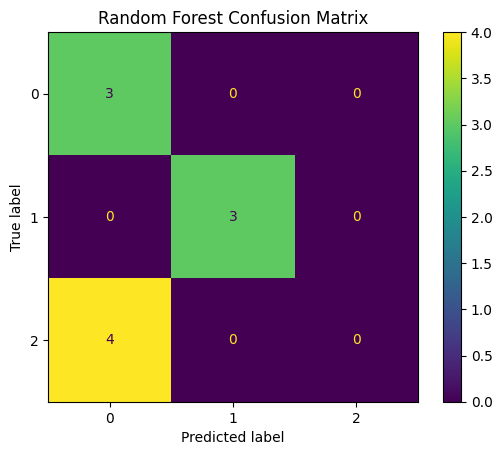

--- Sample Prediction ---
Input Data: [[2, 6, 5, 55]]
Final Predicted Stress Level: High

--- Confidence Breakdown ---
High: 55.75%
Low: 0.00%
Medium: 44.25%
--- Exporting Model ---
Model successfully saved as StressLevel_RandomForest.mlmodel


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import coremltools as ct

path = "/content/drive/MyDrive/datasets/studentStress.csv"
dataset = pd.read_csv(path)

print("Dataset Head:")
print(dataset.head(), "\n")

X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 4].values

# Split into 70% training and 30% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

num_trees = 20
seed = 3

model = RandomForestClassifier(
    n_estimators=2,
    max_depth=1,
    max_features=1,
    min_samples_leaf=15,
    random_state=seed
)
model.fit(X_train, y_train)

print("Cross Validation Results")
kfold = KFold(n_splits=7, random_state=seed, shuffle=True)
cv_results = cross_val_score(model, X, y, cv=kfold)
print("Generated Classifiers CV Scores:", cv_results)
print("Final Model Aggregated CV Mean:", cv_results.mean(), "\n")

print("Test Set Evaluation")
y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred), "\n")

cm_display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred))
cm_display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

sample_data = [[2, 6, 5, 55]]

# 1. Get the final predicted label (High, Medium, or Low)
test_predict = model.predict(sample_data)

# 2. Get the exact confidence percentages for ALL classes
confidence_scores = model.predict_proba(sample_data)

print("--- Sample Prediction ---")
print(f"Input Data: {sample_data}")
print(f"Final Predicted Stress Level: {test_predict[0]}\n")

print("--- Confidence Breakdown ---")
# model.classes_ contains the names of your categories (e.g., ['High', 'Low', 'Medium'])
for category, confidence in zip(model.classes_, confidence_scores[0]):
    # Multiply by 100 and format to 2 decimal places for a clean percentage
    print(f"{category}: {confidence * 100:.2f}%")
print("--- Exporting Model ---")
mlmodel = ct.converters.sklearn.convert(model)
mlmodel.save("StressLevel_RandomForest.mlmodel")
print("Model successfully saved as StressLevel_RandomForest.mlmodel")

Dataset Head:
   study_hours  sleep_hours  social_media_hours  exam_score stress_level
0            2            6                   5          55         High
1            5            7                   2          75          Low
2            1            5                   6          45         High
3            4            6                   3          70       Medium
4            6            8                   1          85          Low 

Cross Validation Results
Generated Classifiers CV Scores: [1. 1. 1. 1. 1. 1. 1.]
Final Model Aggregated CV Mean: 1.0 

Test Set Evaluation
Confusion Matrix:
 [[3 0 0]
 [0 3 0]
 [0 0 4]]

Classification Report:
               precision    recall  f1-score   support

        High       1.00      1.00      1.00         3
         Low       1.00      1.00      1.00         3
      Medium       1.00      1.00      1.00         4

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted 

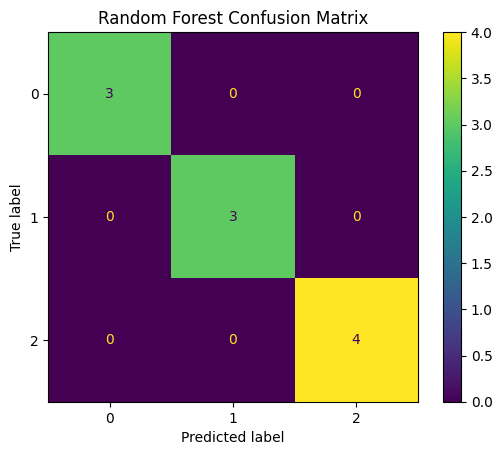

--- Sample Prediction ---
Input Data: [[2, 6, 5, 55]]
Final Predicted Stress Level: High

--- Confidence Breakdown ---
High: 70.00%
Low: 0.00%
Medium: 30.00%


--- Exporting Model ---
Model successfully saved as StressLevel_RandomForest.mlmodel


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import coremltools as ct

path = "/content/drive/MyDrive/datasets/studentStress.csv"
dataset = pd.read_csv(path)

print("Dataset Head:")
print(dataset.head(), "\n")

X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 4].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

num_trees = 20
seed = 3

model = RandomForestClassifier(
    n_estimators=num_trees,
    max_features='sqrt',
    max_depth=2,
    min_samples_leaf=10,
    random_state=seed
)
model.fit(X_train, y_train)

print("Cross Validation Results")
kfold = KFold(n_splits=7, random_state=seed, shuffle=True)
cv_results = cross_val_score(model, X, y, cv=kfold)
print("Generated Classifiers CV Scores:", cv_results)
print("Final Model Aggregated CV Mean:", cv_results.mean(), "\n")

print("Test Set Evaluation")
y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Accuracy Score:", accuracy_score(y_test, y_pred), "\n")

cm_display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred))
cm_display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

sample_data = [[2, 6, 5, 55]]

test_predict = model.predict(sample_data)

confidence_scores = model.predict_proba(sample_data)

print("--- Sample Prediction ---")
print(f"Input Data: {sample_data}")
print(f"Final Predicted Stress Level: {test_predict[0]}\n")

print("--- Confidence Breakdown ---")
for category, confidence in zip(model.classes_, confidence_scores[0]):
    print(f"{category}: {confidence * 100:.2f}%")
print("\n")

print("--- Exporting Model ---")
mlmodel = ct.converters.sklearn.convert(model)
mlmodel.save("StressLevel_RandomForest.mlmodel")
print("Model successfully saved as StressLevel_RandomForest.mlmodel")

Dataset Head:
   study_hours  sleep_hours  social_media_hours  exam_score stress_level
0            2            6                   5          55         High
1            5            7                   2          75          Low
2            1            5                   6          45         High
3            4            6                   3          70       Medium
4            6            8                   1          85          Low 

Cross Validation Results
Generated Classifiers CV Scores: [1. 1. 1. 1. 1. 1. 1.]
Final Model Aggregated CV Mean: 1.0 

Test Set Evaluation
Confusion Matrix:
 [[3 0 0]
 [0 3 0]
 [0 0 4]]

Classification Report:
               precision    recall  f1-score   support

        High       1.00      1.00      1.00         3
         Low       1.00      1.00      1.00         3
      Medium       1.00      1.00      1.00         4

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted 

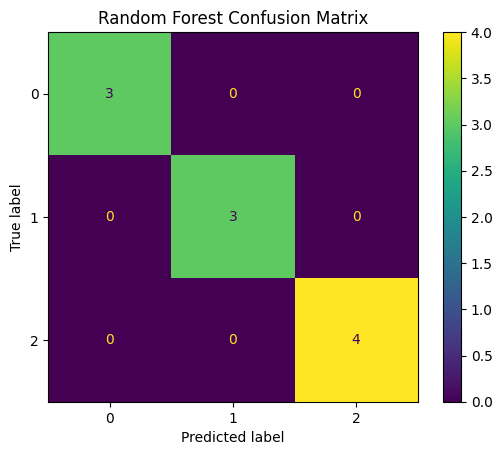

Single Sample Prediction
Input Data: [[2, 6, 5, 55]]
Final Predicted Stress Level: High

Confidence Breakdown
High: 70.00%
Low: 0.00%
Medium: 30.00%


Exporting Model
Model successfully saved as StressLevel_RandomForest.mlmodel


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import coremltools as ct

path = "/content/drive/MyDrive/datasets/studentStress.csv"
dataset = pd.read_csv(path)

print("Dataset Head:")
print(dataset.head(), "\n")

X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, 4].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42)

num_trees = 20
seed = 3

model = RandomForestClassifier(
    n_estimators=num_trees,
    max_features='sqrt',
    max_depth=2,
    min_samples_leaf=10,
    random_state=seed
)
model.fit(X_train, y_train)

print("Cross Validation Results")
kfold = KFold(n_splits=7, random_state=seed, shuffle=True)
cv_results = cross_val_score(model, X, y, cv=kfold)
print("Generated Classifiers CV Scores:", cv_results)
print("Final Model Aggregated CV Mean:", cv_results.mean(), "\n")

print("Test Set Evaluation")
y_pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

test_acc = accuracy_score(y_test, y_pred)
all_probabilities = model.predict_proba(X_test)
avg_confidence = np.mean(np.max(all_probabilities, axis=1))

print("\n Overall Model Performance")
print(f"Overall Test Accuracy:      {test_acc * 100:.2f}%")
print(f"Overall Average Confidence: {avg_confidence * 100:.2f}%")
print("---------------------------------\n")

cm_display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred))
cm_display.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

sample_data = [[2, 6, 5, 55]]
test_predict = model.predict(sample_data)
confidence_scores = model.predict_proba(sample_data)

print("Single Sample Prediction")
print(f"Input Data: {sample_data}")
print(f"Final Predicted Stress Level: {test_predict[0]}\n")

print("Confidence Breakdown")
for category, confidence in zip(model.classes_, confidence_scores[0]):
    print(f"{category}: {confidence * 100:.2f}%")
print("\n")

print("Exporting Model")
mlmodel = ct.converters.sklearn.convert(model)
mlmodel.save("StressLevel_RandomForest.mlmodel")
print("Model successfully saved as StressLevel_RandomForest.mlmodel")

In [ ]:
import pickle

filename = '/content/drive/MyDrive/datasets/stress_level.pkl'

pickle.dump(model, open(filename, 'wb'))

In [ ]:
loaded_model =pickle.load(open(filename,'rb'))

result = loaded_model.predict([[4,6,3,70]])

print(result)

['Medium']
